## Feature Engineering – Customer Segmentation

### Importing libraries


In [1]:
import pandas as pd
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from datetime import datetime

### Load raw data from csv

In [3]:
df = pd.read_csv('customer_segmentation_data.csv') 
print("Initial shape:", df.shape)

Initial shape: (1000, 9)


### A sample of the data set



In [5]:
df.sample(5)

,id,age,gender,income,spending_score,membership_years,purchase_frequency,preferred_category,last_purchase_amount
567,568,45,Female,41917,58,8,5,Home & Garden,870.38
791,792,18,Other,140475,38,8,7,Sports,442.42
745,746,60,Male,34657,99,10,3,Electronics,983.30
249,250,47,Male,91491,52,5,10,Home & Garden,21.43
869,870,57,Other,112212,6,6,44,Home & Garden,312.64


###  Separate features for modelling / clustering

In [20]:
X = df.drop(columns=['CustomerID'], errors='ignore')

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

### Value counts for a specif categorical column

In [8]:
df['preferred_category'].value_counts()


preferred_category
Electronics      215
Sports           210
Home & Garden    206
Groceries        199
Clothing         170
Name: count, dtype: int64

### Visualing with a Pie Chart


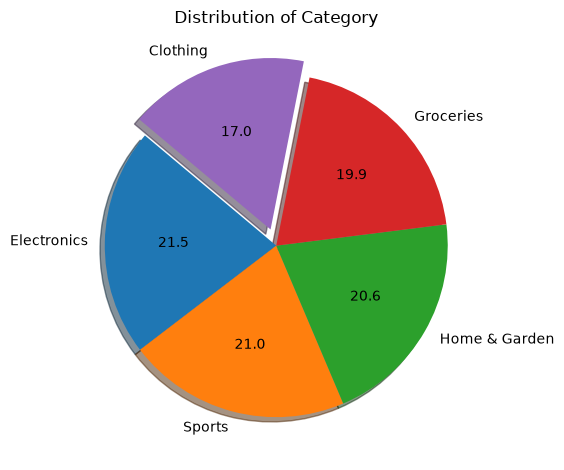

In [9]:
df['preferred_category'].value_counts().plot(kind='pie',autopct="%1.1f",startangle=140,explode = (0, 0, 0, 0,.1),shadow=True)
plt.title('Distribution of Category')
plt.ylabel('')
plt.tight_layout()
plt.show()

### A Pie Chart for distribution of gender


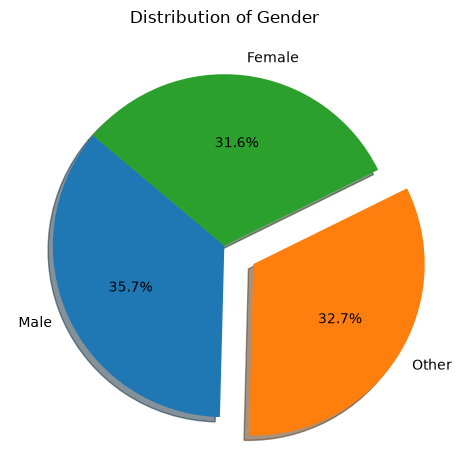

In [10]:
df['gender'].value_counts().plot(kind='pie',autopct="%1.1f%%",startangle=140,explode = (0, 0.2,0),shadow=True)
plt.title('Distribution of Gender')
plt.ylabel('')
plt.tight_layout()
plt.show()

### Correlation Matrix Visual


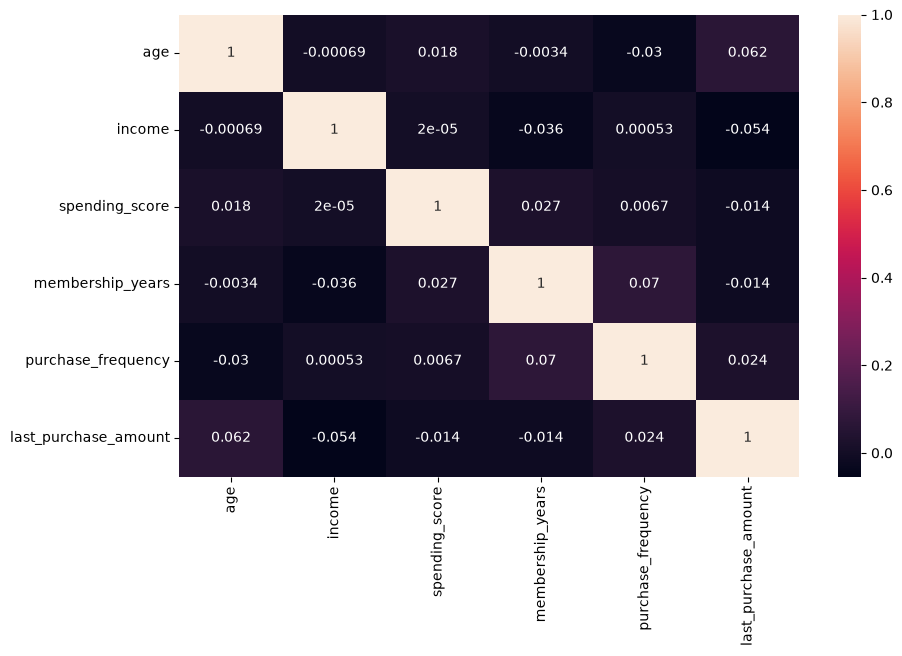

In [13]:
plt.figure(figsize=(10,6))
correlation_matrix = numeric_df.corr()
sns.heatmap(correlation_matrix, annot=True)
plt.show()

<Figure size 1200x600 with 0 Axes>

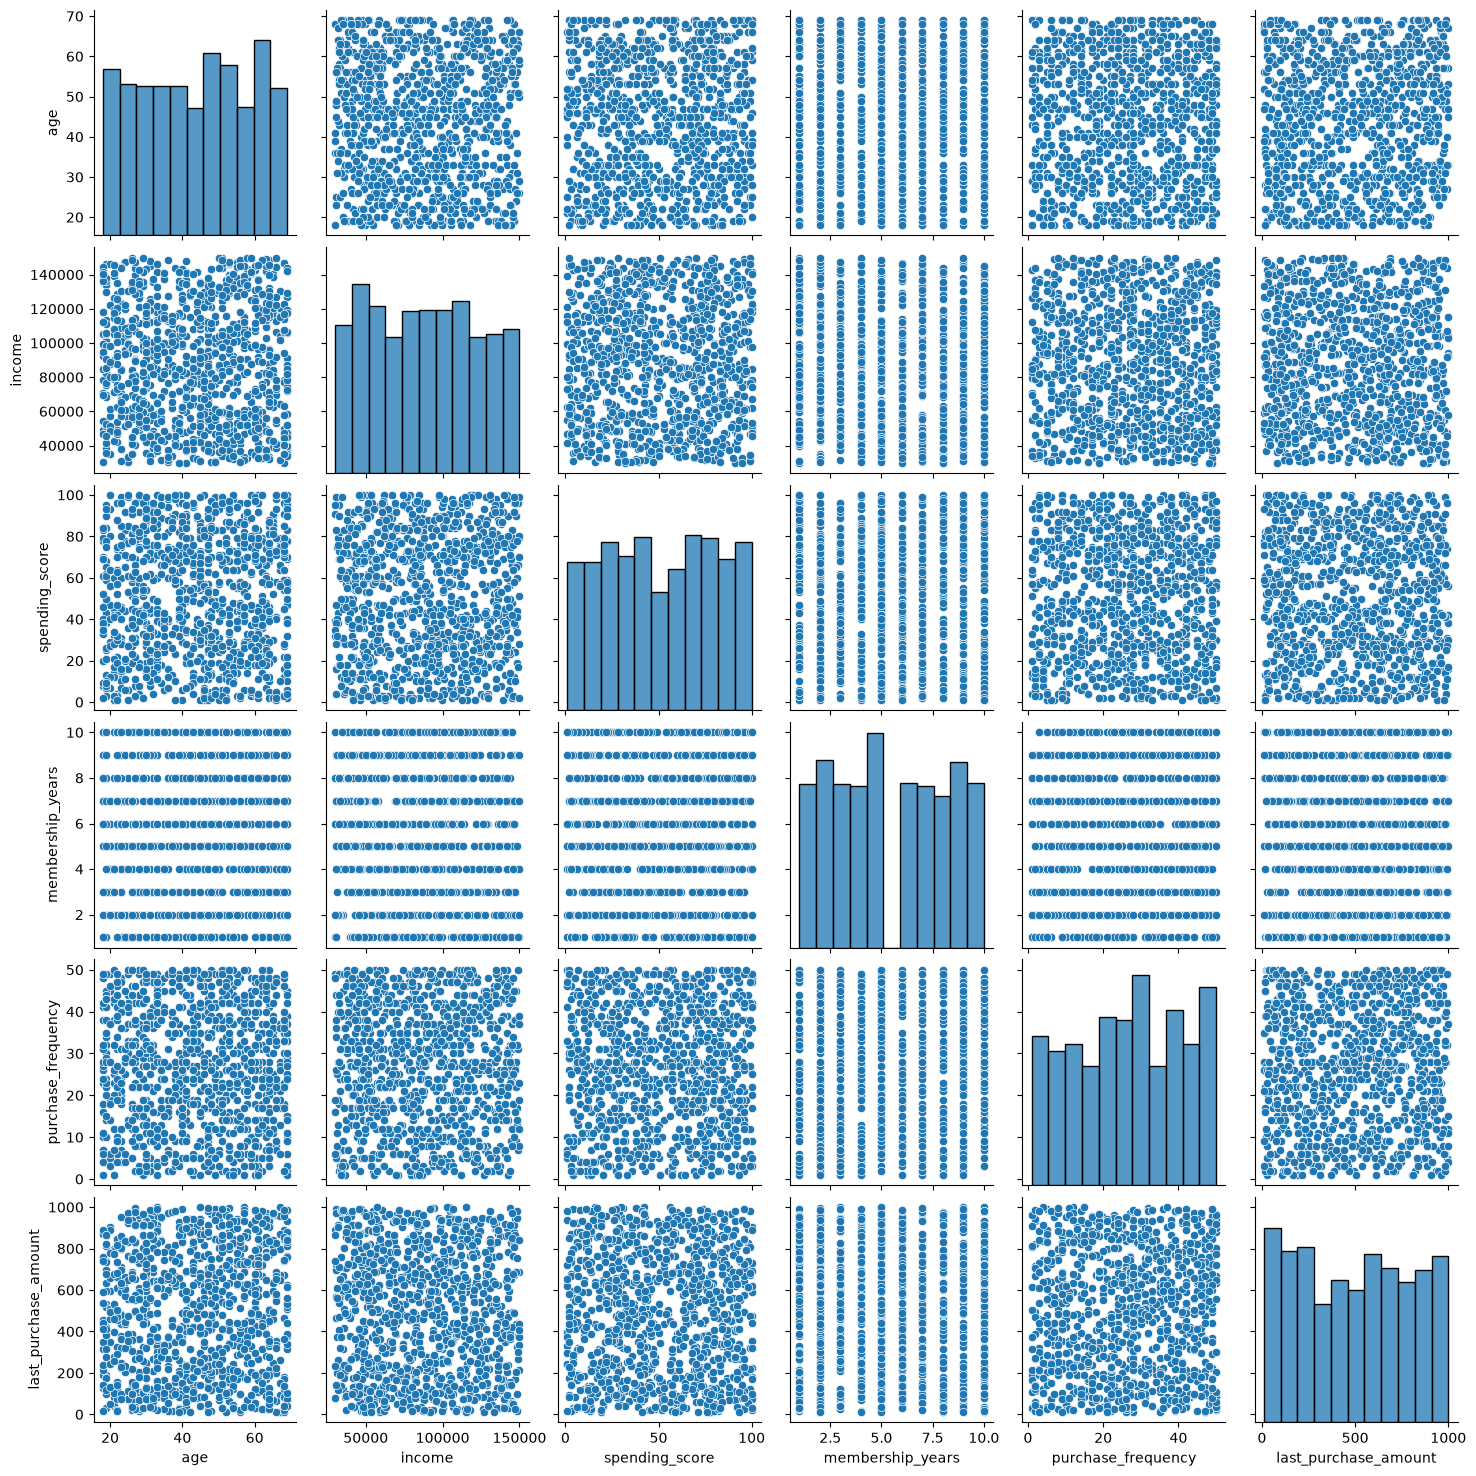

In [14]:
import warnings 
warnings.filterwarnings('ignore')
plt.figure(figsize=(12,6))
sns.pairplot(data=df)
plt.show()

### Identify column types

In [25]:
numeric_features = ['purchase_frequency', 'income', 'membership_years', 'last_purchase_amount', 'age']
categorical_features = ['gender', 'preferred_category']

### Build preprocessing pipeline (scaling + encoding)

In [26]:
numeric_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='drop'
)

### Fit and transform the data

In [27]:
X_processed = preprocessor.fit_transform(X)
print("Processed shape:", X_processed.shape)

Processed shape: (1000, 13)
